# 3. Gene selection under nested cross-validation: the results

This notebook reads the runs that notebook 2 saved and shows what they say: how four ways of choosing a gene list compare under one protocol, what selecting genes outside the cross-validation adds to the score, and which method a rule fixed in advance picks. It holds no modelling code, and every number is read from a saved file. The short version is in the section "Questions from the first meeting, answered", near the end. If the saved runs are missing, the first check stops it.

## Settings

The first cell loads the libraries and locates the saved runs; the two constants below belong to the tables of this notebook, not to the runs. The check after it stops the notebook when notebook 2 has not run.

In [1]:
import hashlib
import json
import subprocess
import sys
from importlib.metadata import version
from itertools import combinations
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from scipy import stats

pd.set_option("display.width", 200)  # a wide table is printed with one line per row
pd.set_option("display.max_colwidth", 100)  # row labels are sentences; do not cut them


def git(*arguments):
    """The output of a git command run in this repository."""
    completed = subprocess.run(["git", *arguments], capture_output=True, text=True, check=True)
    return completed.stdout.strip()


REPO = Path(git("rev-parse", "--show-toplevel"))
RUNS = REPO / "results" / "02_gene_selection_runs"       # the saved runs of notebook 2
FIRST_RUN = RUNS / "first_run"                            # the saved runs of the first run
DATA_RESULTS = REPO / "results" / "01_data"               # gene symbols
RESULTS = REPO / "results" / "03_gene_selection_results"  # the tables of this notebook, tracked
STABLE_SHARE = 0.8  # a gene counts as stable when at least 80% of the lists contain it
TOP_GENES = 20      # most often selected genes shown per method

In [2]:
# Without the saved runs of notebook 2 there is nothing to show.
missing = []
for name in ["settings.json", "what_is_compared.csv", "shuffled_outcome_check.json"]:
    if not (RUNS / name).exists():
        missing.append(name)
assert not missing, f"run notebooks/02_gene_selection_runs.ipynb first; missing: {missing}"

## Settings of the runs

Notebook 2 saved every fold count, seed, threshold and grid it used, each with a phrase saying what it is. The table shows them, and the names this notebook needs are taken from the same file, so the two notebooks cannot drift apart.

In [3]:
def show_table(rows, first_column):
    """Render a dictionary of rows as a Markdown table, which wraps long sentences."""
    columns = list(next(iter(rows.values())))
    header = "| " + first_column + " | " + " | ".join(columns) + " |"
    lines = [header]
    lines.append("|---" * (len(columns) + 1) + "|")
    for name, row in rows.items():
        cells = [name]
        for column in columns:
            cells.append(str(row[column]))
        lines.append("| " + " | ".join(cells) + " |")
    display(Markdown("\n".join(lines)))


settings = json.loads((RUNS / "settings.json").read_text())
OUTER_FOLDS = settings["outer folds"]["value"]
INNER_FOLDS = settings["inner folds"]["value"]
CONFIDENCE = settings["confidence"]["value"]
RIDGE_GRID = settings["ridge grid"]["value"]
FORMS = settings["forms"]["value"]
INSIDE = settings["arms"]["value"]["inside"]
ON_ALL = settings["arms"]["value"]["on all"]
SELECTION_METHODS = settings["selection methods"]["value"]
LEAKAGE_LIST_SIZE = settings["leakage list size"]["value"]
shown_settings = {}
for name, saved_setting in settings.items():
    shown_settings[name] = {"value": json.dumps(saved_setting["value"]),
                            "what it is": saved_setting["what it is"]}
show_table(shown_settings, "setting")

| setting | value | what it is |
|---|---|---|
| outer folds | 5 | folds of the outer cross-validation; each is held out once per repeat |
| outer seeds | [1, 2, 3, 4, 5] | one seed per repeat of the outer cross-validation |
| inner folds | 5 | folds inside each outer training part that choose the settings of a method |
| inner seed | 0 | seed of the inner split |
| list sizes | [50, 100, 200, 500, 1000, 2000] | list lengths offered to the two ranking methods |
| L1 shares | [0.25, 0.5, 0.75] | mix of the elastic-net penalty; 1 is pure LASSO, 0 pure ridge |
| path length | 50 | penalties per path of LASSO-Cox and elastic-net Cox |
| path depth | 0.01 | smallest penalty of a path as a share of the largest |
| longest list | 2000 | longest list a penalty path may offer |
| ridge grid | [1.0, 10.0, 100.0, 1000.0, 10000.0] | ridge penalties offered to the scoring model |
| clinical ridge | 0.001 | ridge on the clinical columns of the scoring model, a numerical safeguard |
| leakage list size | 100 | list length of the one-gene Cox ranking in the leakage and shuffled-outcome checks |
| shuffle seeds | [1, 2, 3, 4, 5] | one seed per shuffle of the outcomes in the shuffled-outcome check |
| confidence | 0.95 | level of every interval |
| expressed log2 | 1.0 | a gene is expressed in a patient at this log2(TPM + 1) or above |
| expressed share | 0.2 | share of training patients in which a gene must be expressed to pass the filter |
| Uno horizon (years) | 5.0 | Uno's C counts pairs up to this time after diagnosis |
| clinical levels | {"stage": ["I", "III", "IV", "unknown"], "er": ["negative", "unknown"], "pr": ["negative", "unknown"], "her2": ["positive", "unknown"]} | indicator columns of the clinical model per covariate; the most common level is the reference |
| forms | {"genes only": "genes_only", "genes plus clinical": "genes_plus_clinical"} | the two forms of the scoring model and their key in the saved runs |
| arms | {"inside": "selection inside the training fold", "on all": "selection on all patients"} | the two ways of selecting that the leakage check contrasts |
| selection methods | ["most variable genes", "one-gene Cox ranking", "LASSO-Cox", "elastic-net Cox"] | the four methods that are candidates for the choice at the end |

## What is compared

The table names everything that was compared and says whether it looks at patient outcomes when it picks genes. Four rows are selection methods. Three are references: they appear in the tables and are not candidates for the choice at the end. The last row names the selector of the earlier pipeline, which was not run.

In [4]:
compared = pd.read_csv(RUNS / "what_is_compared.csv", index_col=0)
compared_rows = {}
for name, row in compared.iterrows():
    compared_rows[name] = dict(row)
show_table(compared_rows, "name")
METHOD_NAMES = []
for name, role in compared["role"].items():
    if role != "not run":
        METHOD_NAMES.append(name)

| name | what it does | uses patient outcomes to pick genes | role |
|---|---|---|---|
| clinical only | no gene: a Cox model on age, stage, ER, PR and HER2 | picks no genes | reference |
| clinical only, unknown values replaced | as clinical only, with every unknown value replaced by the most common known level of the training part | picks no genes | reference |
| most variable genes | ranks genes by the variance of their expression and keeps the top of the ranking | no | selection method |
| one-gene Cox ranking | ranks genes by a test of each gene alone in a Cox model and keeps the top of the ranking | yes | selection method |
| LASSO-Cox | fits one Cox model on all genes with a penalty that sets most coefficients to zero; the remaining genes are the list | yes | selection method |
| elastic-net Cox | as LASSO-Cox, with a mixed penalty that lets correlated genes enter together | yes | selection method |
| all genes | no selection: the scoring model on every gene that passes the expression filter | picks no genes | reference |
| the earlier pipeline's selector | LASSO on survival classes, as in the earlier pipeline; not run, because its built-in cross-validation exceeds the compute budget of this study | yes, as classes | not run |

## Reading the saved runs

A saved run holds one record per outer fold: for each form of the scoring model, Harrell's C and Uno's C on the held-out fold, the chosen setting and ridge, the list length, whether the list was the shortest or the longest on offer, and for the selection methods the list itself. The function below reads one run as a table.

In [5]:
def load_run(folder, *name_parts):
    """The records of a saved run as a table, one row per outer fold."""
    name = "_".join(name_parts).lower().replace("-", "_").replace(",", "").replace(" ", "_")
    path = folder / (name + ".json")
    assert path.exists(), f"saved run missing: {path.name}; run notebook 2 first"
    return pd.DataFrame(json.loads(path.read_text())["result"])


def tidy(table):
    """A table for reading: missing values blank, whole numbers as integers, others rounded."""
    shown = table.copy().astype(object)
    for column in table.columns:
        for row in table.index:
            value = table.at[row, column]
            if not isinstance(value, (float, np.floating)):
                continue
            if np.isnan(value):
                shown.at[row, column] = ""
            elif float(value).is_integer():
                shown.at[row, column] = int(value)
            else:
                shown.at[row, column] = f"{value:.3f}"
    return shown


runs = {}
for name in METHOD_NAMES:
    runs[name] = load_run(RUNS, "method comparison", name)
RESULTS.mkdir(parents=True, exist_ok=True)
display(Markdown(f"{len(runs)} runs of the method comparison read, {len(runs['clinical only'])} "
                 "outer folds each."))

7 runs of the method comparison read, 25 outer folds each.

## Shuffled-outcome check

Before any real outcome was modelled, notebook 2 shuffled the outcomes across patients, which destroys every true link between genes and survival, and ran the one-gene Cox ranking both ways: with selection inside the training fold, and with selection on all patients before the cross-validation. A correct pipeline scores about 0.5 with selection inside the training fold. The other row shows how much score can appear from selection alone.

In [6]:
def t_interval(values):
    """Mean and t interval of a few independent values."""
    values = np.asarray(values, dtype=float)
    spread = values.std(ddof=1) / np.sqrt(len(values))
    half = stats.t.ppf((1 + CONFIDENCE) / 2, len(values) - 1) * spread
    return values.mean(), values.mean() - half, values.mean() + half


def shuffled_check_table(rows):
    """Mean C per arm over the shuffles, with its t interval."""
    table = {}
    for arm in [INSIDE, ON_ALL]:
        arm_rows = rows[rows["arm"] == arm]
        means = arm_rows.groupby("shuffle")["harrell_genes_only"].mean()
        mean, low, high = t_interval(means)
        table[arm] = {"mean C": mean, "interval low": low, "interval high": high}
    return pd.DataFrame.from_dict(table, orient="index")


shuffled_table = shuffled_check_table(load_run(RUNS, "shuffled-outcome check"))
shuffled_table.to_csv(RESULTS / "shuffled_outcome_check_table.csv")
tidy(shuffled_table)

,mean C,interval low,interval high
selection inside the training fold,0.524,0.475,0.573
selection on all patients,0.665,0.621,0.709


## Method comparison

The first table is for the scoring model with genes only: the four selection methods and the all-genes reference, with the mean and standard deviation of Harrell's C over the outer folds, the mean of Uno's C and the median length of the chosen lists. The sentence under it says which method scores highest and how far apart the four are.

In [7]:
def summarise(folds):
    """Mean and SD of Harrell's C, mean Uno's C and median list length, per form of the model."""
    row = {}
    for form, key in FORMS.items():
        has_genes = folds["list_length_" + key].max() > 0
        if has_genes or form == "genes plus clinical":
            row[form + ": Harrell's C"] = folds["harrell_" + key].mean()
            row[form + ": SD"] = folds["harrell_" + key].std()
            row[form + ": Uno's C"] = folds["uno_" + key].mean()
            row[form + ": genes, median"] = folds["list_length_" + key].median()
        else:
            row[form + ": Harrell's C"] = np.nan
            row[form + ": SD"] = np.nan
            row[form + ": Uno's C"] = np.nan
            row[form + ": genes, median"] = np.nan
    return row


def form_table(form, names):
    """The results of one form of the scoring model, one row per method."""
    new_names = {form + ": Harrell's C": "Harrell's C (mean)", form + ": SD": "SD over the folds",
                 form + ": Uno's C": "Uno's C (mean)",
                 form + ": genes, median": "genes in the list (median)"}
    return results_table.loc[names, list(new_names)].rename(columns=new_names)

In [8]:
results_rows = {}
for name, folds in runs.items():
    results_rows[name] = summarise(folds)
results_table = pd.DataFrame.from_dict(results_rows, orient="index")
results_table.to_csv(RESULTS / "method_comparison_results.csv")  # both forms in one file
HARRELL = "Harrell's C (mean)"
genes_only_table = form_table("genes only", SELECTION_METHODS + ["all genes"])
genes_only_table.to_csv(RESULTS / "method_comparison_genes_only.csv")
display(tidy(genes_only_table))
method_scores = genes_only_table.loc[SELECTION_METHODS, HARRELL]
best_genes_only = method_scores.idxmax()
spread_of_methods = method_scores.max() - method_scores.min()
all_genes_score = genes_only_table.at["all genes", HARRELL]
display(Markdown(f"With genes only, {best_genes_only} scores highest of the four selection "
                 f"methods, {method_scores.max():.3f}; the four lie within {spread_of_methods:.3f} "
                 f"of each other, and the all-genes reference scores {all_genes_score:.3f}."))

,Harrell's C (mean),SD over the folds,Uno's C (mean),genes in the list (median)
most variable genes,0.657,0.059,0.662,2000
one-gene Cox ranking,0.651,0.062,0.664,2000
LASSO-Cox,0.649,0.067,0.653,174
elastic-net Cox,0.659,0.073,0.663,384
all genes,0.689,0.066,0.709,14321


With genes only, elastic-net Cox scores highest of the four selection methods, 0.659; the four lie within 0.010 of each other, and the all-genes reference scores 0.689.

The second table is for the scoring model with genes plus clinical. The two clinical-only rows use no gene; they are the references that the other five rows must beat. The sentence under it counts how many of the gene models score above the clinical-only reference.

In [9]:
references = ["clinical only", "clinical only, unknown values replaced"]
gene_models = SELECTION_METHODS + ["all genes"]
plus_clinical_table = form_table("genes plus clinical", references + gene_models)
plus_clinical_table.to_csv(RESULTS / "method_comparison_genes_plus_clinical.csv")
display(tidy(plus_clinical_table))
reference_score = plus_clinical_table.at["clinical only", HARRELL]
reference_uno = plus_clinical_table.at["clinical only", "Uno's C (mean)"]
replaced_score = plus_clinical_table.at[references[1], HARRELL]
gene_model_scores = plus_clinical_table.loc[gene_models, HARRELL]
above_reference = int((gene_model_scores > reference_score).sum())
display(Markdown(f"The clinical-only reference scores {reference_score:.3f} ({reference_uno:.3f} "
                 f"on Uno's C); with unknown values replaced it scores {replaced_score:.3f}. The "
                 f"five models with genes plus clinical score {gene_model_scores.min():.3f} to "
                 f"{gene_model_scores.max():.3f}; {above_reference} of the {len(gene_models)} lie "
                 "above the reference."))

,Harrell's C (mean),SD over the folds,Uno's C (mean),genes in the list (median)
clinical only,0.740,0.052,0.699,0
"clinical only, unknown values replaced",0.721,0.062,0.675,0
most variable genes,0.730,0.061,0.690,100
one-gene Cox ranking,0.721,0.069,0.687,50
LASSO-Cox,0.733,0.057,0.701,162
elastic-net Cox,0.728,0.063,0.697,265
all genes,0.716,0.074,0.702,14321


The clinical-only reference scores 0.740 (0.699 on Uno's C); with unknown values replaced it scores 0.721. The five models with genes plus clinical score 0.716 to 0.733; 0 of the 5 lie above the reference.

The figure answers one question: how the held-out score of each gene model spreads over the outer folds when the scoring model uses genes only, against the clinical-only reference, which uses no gene. Each dot is one fold, the box spans the middle half of the folds with the median as a line, and the dotted line is chance. Compare the spread within a method with the gaps between methods.

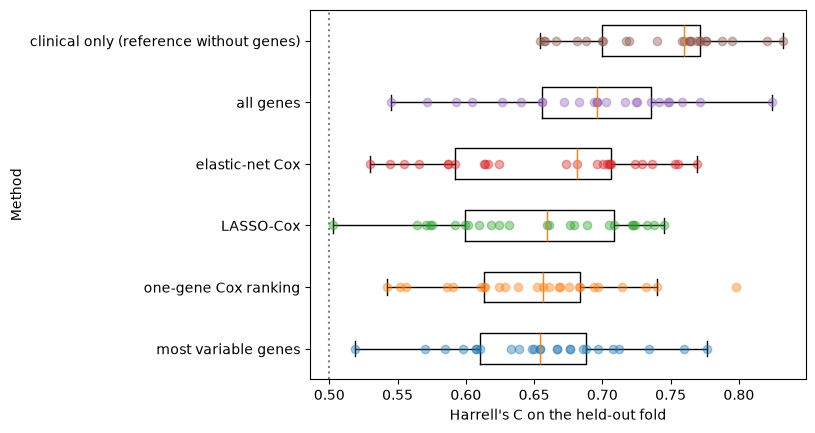

In [10]:
tuned_methods = []
for name in METHOD_NAMES:
    if runs[name]["list_length_genes_only"].max() > 0:
        tuned_methods.append(name)
figure_labels = []
scores_by_row = []
for name in tuned_methods:
    figure_labels.append(name)
    scores_by_row.append(runs[name]["harrell_genes_only"])
figure_labels.append("clinical only (reference without genes)")
scores_by_row.append(runs["clinical only"]["harrell_genes_plus_clinical"])
figure, axis = plt.subplots()
axis.boxplot(scores_by_row, orientation="horizontal", showfliers=False)
for position, scores in enumerate(scores_by_row, start=1):
    axis.plot(scores, np.full(len(scores), position), "o", alpha=0.4)  # see-through dots overlap
axis.axvline(0.5, linestyle=":", color="grey")  # chance level
axis.set_yticks(range(1, len(figure_labels) + 1), figure_labels)
axis.set_xlabel("Harrell's C on the held-out fold")
axis.set_ylabel("Method")
plt.show()

## Paired comparisons

Two scores from the same fold share the same patients, so methods are compared by their difference on each fold. The training parts of repeated cross-validation overlap, which makes an ordinary t interval too narrow; the corrected resampled t interval of Nadeau and Bengio (Machine Learning 2003, doi:10.1023/A:1024068626366, read in its 1999 conference version), in the form for repeated cross-validation of Bouckaert and Frank (PAKDD 2004, doi:10.1007/978-3-540-24775-3_3, read in the authors' working paper), widens it. The primary comparison, fixed in advance: elastic-net Cox lists against LASSO-Cox lists, a null if the interval includes 0.

In [11]:
def corrected_interval(differences):
    """Mean difference over repeated cross-validation folds, with the corrected t interval."""
    differences = np.asarray(differences, dtype=float)
    count = len(differences)
    correction = 1 / count + 1 / (OUTER_FOLDS - 1)  # 1 / (folds - 1) = test size over training size
    spread = np.sqrt(correction * differences.var(ddof=1))
    half = stats.t.ppf((1 + CONFIDENCE) / 2, count - 1) * spread
    return differences.mean(), differences.mean() - half, differences.mean() + half


def difference_row(left, right):
    """The mean paired difference of two per-fold series, its interval and whether it includes 0."""
    difference, low, high = corrected_interval(left - right)
    return {"difference": difference, "interval low": low, "interval high": high,
            "interval includes 0": low <= 0 <= high}


def primary_comparison(runs):
    """One sentence on elastic-net Cox against LASSO-Cox, genes only."""
    row = difference_row(runs["elastic-net Cox"]["harrell_genes_only"],
                         runs["LASSO-Cox"]["harrell_genes_only"])
    if row["interval includes 0"]:
        verdict = ("includes 0, so the result is null: the elastic net is not shown to beat LASSO "
                   "here")
    else:
        verdict = "excludes 0, so the two methods differ"
    return (f"elastic-net Cox minus LASSO-Cox, genes only, is {row['difference']:+.3f} on average, "
            f"{CONFIDENCE:.0%} interval {row['interval low']:+.3f} to {row['interval high']:+.3f}; "
            f"the interval {verdict}")


primary_sentence = primary_comparison(runs)
display(Markdown(f"Primary comparison: {primary_sentence}."))

Primary comparison: elastic-net Cox minus LASSO-Cox, genes only, is +0.010 on average, 95% interval -0.039 to +0.058; the interval includes 0, so the result is null: the elastic net is not shown to beat LASSO here.

The table lists every paired comparison on both metrics: Harrell's C is the primary metric and Uno's C, which corrects for censoring, the secondary one. A cell gives the mean difference with its interval as "difference (low to high)"; the last column says whether the comparison was fixed in advance or is exploratory. The secondary comparisons, fixed in advance, ask whether a selected gene list adds to the clinical covariates: genes plus clinical against clinical only on the same folds. The sentence under the table counts the intervals that include 0.

In [12]:
PLANNED = {"registered": "fixed in advance", "exploratory": "exploratory"}
METRICS = [("Harrell's C", "harrell_"), ("Uno's C, secondary", "uno_")]
comparisons = []
comparisons.append(("elastic-net Cox minus LASSO-Cox, genes only", "elastic-net Cox", "genes_only",
                    "LASSO-Cox", "genes_only", "registered"))
for name in SELECTION_METHODS:
    comparisons.append((name + " plus clinical minus clinical only", name, "genes_plus_clinical",
                        "clinical only", "genes_plus_clinical", "registered"))
comparisons.append(("all genes plus clinical minus clinical only", "all genes",
                    "genes_plus_clinical", "clinical only", "genes_plus_clinical", "exploratory"))
comparisons.append(("all genes, genes only, minus clinical only", "all genes", "genes_only",
                    "clinical only", "genes_plus_clinical", "exploratory"))
comparisons.append(("all genes minus most variable genes, genes only", "all genes", "genes_only",
                    "most variable genes", "genes_only", "exploratory"))
unknown_replaced = ("clinical only, unknown values replaced, minus clinical only",
                    "clinical only, unknown values replaced", "genes_plus_clinical",
                    "clinical only", "genes_plus_clinical", "exploratory")

In [13]:
# This file keeps the layout of an earlier table; the table shown is the one after it.
clinical_only = runs["clinical only"]["harrell_genes_plus_clinical"]
against_clinical_rows = {}
for name in SELECTION_METHODS + ["all genes", "clinical only, unknown values replaced"]:
    row = difference_row(runs[name]["harrell_genes_plus_clinical"], clinical_only)
    row["difference to clinical only"] = row.pop("difference")
    row["status"] = "exploratory"
    if name in SELECTION_METHODS:
        row["status"] = "registered"
    against_clinical_rows[name] = row
columns = ["difference to clinical only", "interval low", "interval high", "interval includes 0",
           "status"]
against_clinical = pd.DataFrame.from_dict(against_clinical_rows, orient="index")[columns]
against_clinical.to_csv(RESULTS / "method_comparison_against_clinical_only.csv")

In [14]:
def interval_text(cells):
    """A mean difference with its interval, written as difference (low to high)."""
    return (f"{cells['difference']:+.3f} ({cells['interval low']:+.3f} to "
            f"{cells['interval high']:+.3f})")


both_metrics_rows = {}
paired_rows = {}
includes_zero = {}
half_widths = []
for label, left, left_form, right, right_form, status in comparisons + [unknown_replaced]:
    both_row = {}
    paired_row = {}
    for metric, prefix in METRICS:
        cells = difference_row(runs[left][prefix + left_form], runs[right][prefix + right_form])
        for cell, value in cells.items():
            both_row[metric + ": " + cell] = value
        paired_row[metric + ": difference (low to high)"] = interval_text(cells)
        includes_zero[metric] = includes_zero.get(metric, 0) + int(cells["interval includes 0"])
        if metric == METRICS[0][0]:
            half_widths.append((cells["interval high"] - cells["interval low"]) / 2)
    both_row["status"] = status
    paired_row["fixed in advance or exploratory"] = PLANNED[status]
    if label != unknown_replaced[0]:
        both_metrics_rows[label] = both_row
    paired_rows[label] = paired_row
both_metrics = pd.DataFrame.from_dict(both_metrics_rows, orient="index")
both_metrics.to_csv(RESULTS / "both_metrics.csv")
paired_table = pd.DataFrame.from_dict(paired_rows, orient="index")
paired_table.to_csv(RESULTS / "paired_comparisons.csv")
show_table(paired_rows, "comparison")

| comparison | Harrell's C: difference (low to high) | Uno's C, secondary: difference (low to high) | fixed in advance or exploratory |
|---|---|---|---|
| elastic-net Cox minus LASSO-Cox, genes only | +0.010 (-0.039 to +0.058) | +0.010 (-0.041 to +0.061) | fixed in advance |
| most variable genes plus clinical minus clinical only | -0.009 (-0.049 to +0.030) | -0.008 (-0.050 to +0.033) | fixed in advance |
| one-gene Cox ranking plus clinical minus clinical only | -0.019 (-0.063 to +0.024) | -0.011 (-0.052 to +0.029) | fixed in advance |
| LASSO-Cox plus clinical minus clinical only | -0.007 (-0.042 to +0.029) | +0.002 (-0.036 to +0.040) | fixed in advance |
| elastic-net Cox plus clinical minus clinical only | -0.011 (-0.056 to +0.034) | -0.001 (-0.049 to +0.047) | fixed in advance |
| all genes plus clinical minus clinical only | -0.024 (-0.078 to +0.031) | +0.004 (-0.056 to +0.064) | exploratory |
| all genes, genes only, minus clinical only | -0.051 (-0.128 to +0.027) | +0.011 (-0.077 to +0.099) | exploratory |
| all genes minus most variable genes, genes only | +0.032 (-0.023 to +0.087) | +0.047 (-0.009 to +0.104) | exploratory |
| clinical only, unknown values replaced, minus clinical only | -0.019 (-0.049 to +0.012) | -0.024 (-0.063 to +0.016) | exploratory |

In [15]:
development = json.loads((DATA_RESULTS / "split.json").read_text())["tcga_development"]
deaths_per_fold = development["deaths"] / OUTER_FOLDS
display(Markdown(f"{includes_zero[METRICS[0][0]]} of the {len(paired_rows)} intervals on Harrell's "
                 f"C include 0, and {includes_zero[METRICS[1][0]]} of {len(paired_rows)} on Uno's "
                 f"C. Each held-out fold holds about {deaths_per_fold:.0f} deaths. The half-widths "
                 f"of the intervals on Harrell's C run from {min(half_widths):.3f} to "
                 f"{max(half_widths):.3f}; a difference smaller than that cannot be shown by this "
                 "comparison."))

9 of the 9 intervals on Harrell's C include 0, and 9 of 9 on Uno's C. Each held-out fold holds about 24 deaths. The half-widths of the intervals on Harrell's C run from 0.030 to 0.078; a difference smaller than that cannot be shown by this comparison.

## Stability

A selection method should also return similar lists when the patients change a little. For each method we compare its genes-only lists from all outer folds pair by pair with the Jaccard index, the size of the overlap of two lists divided by the size of their union (1 means identical lists, 0 no shared gene). We also count the stable genes, those present in at least a fixed share of the lists, given in the sentence under the table.

In [16]:
def jaccard(first, second):
    """The size of the overlap of two lists divided by the size of their union."""
    union = len(set(first) | set(second))
    if union == 0:
        return 1.0  # two empty lists are identical
    return len(set(first) & set(second)) / union


def stability(lists):
    """Mean pairwise Jaccard index, the number of stable genes, and the list lengths."""
    lists = list(lists)
    all_genes = []
    for genes in lists:
        all_genes += list(genes)
    counts = pd.Series(all_genes).value_counts()
    pairwise = []
    for first, second in combinations(lists, 2):
        pairwise.append(jaccard(first, second))
    lengths = [len(genes) for genes in lists]
    return {"mean pairwise Jaccard": np.mean(pairwise),
            "stable genes": int((counts >= STABLE_SHARE * len(lists)).sum()),
            "genes, median": float(np.median(lengths)),
            "genes, range": f"{min(lengths)} to {max(lengths)}"}


stability_rows = {}
for name in SELECTION_METHODS:
    stability_rows[name] = stability(runs[name]["selected_genes_only"])
stability_table = pd.DataFrame.from_dict(stability_rows, orient="index")
stability_table.to_csv(RESULTS / "method_comparison_stability.csv")
display(tidy(stability_table))
lists_per_method = len(runs[SELECTION_METHODS[0]])
display(Markdown(f"A gene counts as stable when at least {STABLE_SHARE:.0%} of the "
                 f"{lists_per_method} lists of a method contain it. Lists of different lengths "
                 "lower the Jaccard index for that reason alone; the range column shows how much "
                 "the lengths vary within each method."))

,mean pairwise Jaccard,stable genes,"genes, median","genes, range"
most variable genes,0.570,953,2000,100 to 2000
one-gene Cox ranking,0.328,462,2000,200 to 2000
LASSO-Cox,0.132,6,174,6 to 233
elastic-net Cox,0.166,35,384,14 to 1328


A gene counts as stable when at least 80% of the 25 lists of a method contain it. Lists of different lengths lower the Jaccard index for that reason alone; the range column shows how much the lengths vary within each method.

The table lists the genes that LASSO-Cox and elastic-net Cox select most often, each with the number of outer-fold lists that contain it. Genes are shown by symbol. It describes the lists of this comparison and is not a final gene list.

In [17]:
symbols = pd.read_csv(DATA_RESULTS / "gene_pool.csv").set_index("gene_id")["symbol"]


def most_selected(lists):
    """The most often selected genes, by symbol, with the number of lists that contain each."""
    selected_symbols = []
    for genes in lists:
        for gene in genes:
            selected_symbols.append(symbols[gene])
    counts = pd.Series(selected_symbols).value_counts().head(TOP_GENES)
    labels = []
    for symbol, count in counts.items():
        labels.append(f"{symbol} ({count})")
    return labels


most_selected_columns = {}
for name in ["LASSO-Cox", "elastic-net Cox"]:
    most_selected_columns[name] = pd.Series(most_selected(runs[name]["selected_genes_only"]))
most_selected_genes = pd.DataFrame(most_selected_columns).fillna("")
most_selected_genes.index = range(1, len(most_selected_genes) + 1)
most_selected_genes.to_csv(RESULTS / "method_comparison_most_selected_genes.csv")
most_selected_genes

,LASSO-Cox,elastic-net Cox
1,NFE2 (24),VSIG1 (24)
2,VSIG1 (23),NFE2 (24)
3,CEL (23),CLEC3A (24)
4,MCTS1 (23),CEL (24)
5,SERPINA1 (22),MCTS1 (24)
6,ST7-AS1 (22),MAP2K6 (23)
7,JCHAIN (19),MRPS2 (23)
8,PELO (19),PELO (23)
9,CLEC3A (19),CYTL1 (23)
10,FAM214B (18),SERPINA1 (23)


## Grid edges

A tuned value at the edge of its grid suggests that the grid was too narrow on that side. An earlier run of this study, described at the end of this notebook, had most tuned values at an edge; the grids were widened for this run. The table counts, per method and form, the outer folds in which the inner folds chose the weakest or the strongest ridge penalty on offer, and the shortest or the longest list. The shortest list of a penalty path is empty, so that column counts the folds without genes.

In [18]:
def edge_counts(folds, key, one_list):
    """How often the inner folds chose the edge of a grid: the ridge ends and the list ends."""
    has_genes = folds["list_length_" + key] > 0  # an empty list has no ridge penalty to choose
    weakest = (folds["ridge_" + key] == RIDGE_GRID[0]) & has_genes
    strongest = (folds["ridge_" + key] == RIDGE_GRID[-1]) & has_genes
    counts = {"outer folds": len(folds),
              "weakest ridge chosen": int(weakest.sum()),
              "strongest ridge chosen": int(strongest.sum())}
    if one_list:
        counts["shortest list chosen"] = "one list only"
        counts["longest list chosen"] = "one list only"
    else:
        counts["shortest list chosen"] = int(folds["shortest_list_" + key].sum())
        counts["longest list chosen"] = int(folds["longest_list_" + key].sum())
    return counts


def edge_cases(form, column):
    """The methods for which the inner folds chose the given grid edge, with the fold counts."""
    phrases = []
    for name in tuned_methods:
        count = grid_edges.at[(name, form), column]
        folds = grid_edges.at[(name, form), "outer folds"]
        if str(count).isdigit() and int(count) > 0:
            phrases.append(f"{name} in {count} of {folds}")
    return ", ".join(phrases) or "no method"


grid_edge_rows = {}
for name in tuned_methods:
    one_list = name not in SELECTION_METHODS
    for form, key in FORMS.items():
        grid_edge_rows[(name, form)] = edge_counts(runs[name], key, one_list)
grid_edges = pd.DataFrame.from_dict(grid_edge_rows, orient="index")
grid_edges.index.names = ["method", "form of the scoring model"]
grid_edges.to_csv(RESULTS / "method_comparison_grid_edges.csv")
grid_edges

outer folds  weakest ridge chosen  strongest ridge chosen shortest list chosen longest list chosen
method               form of the scoring model                                                                                                    
most variable genes  genes only                          25                     3                       0                    0                  16
                     genes plus clinical                 25                     0                       1                    2                   4
one-gene Cox ranking genes only                          25                     4                       0                    0                  19
                     genes plus clinical                 25                     1                      16                   16                   6
LASSO-Cox            genes only                          25                     5                       0                    0                   1
                     genes plus clinical                 25                     0                       5                    1                   2
elastic-net Cox      genes only                          25                     9                       0                    0                   3
                     genes plus clinical                 25                     0                       4                    1                   2
all genes            genes only                          25                     4                       1        one list only       one list only
                     genes plus clinical                 25                     1                      19        one list only       one list only

In [19]:
longest_chosen = edge_cases("genes only", "longest list chosen")
strongest_chosen = edge_cases("genes plus clinical", "strongest ridge chosen")
display(Markdown(f"With genes only, the longest list on offer was chosen for {longest_chosen} "
                 "folds: longer lists might have scored higher, which is a limit of this "
                 "comparison. With genes plus clinical, the strongest ridge penalty on offer was "
                 f"chosen for {strongest_chosen} folds."))

With genes only, the longest list on offer was chosen for most variable genes in 16 of 25, one-gene Cox ranking in 19 of 25, LASSO-Cox in 1 of 25, elastic-net Cox in 3 of 25 folds: longer lists might have scored higher, which is a limit of this comparison. With genes plus clinical, the strongest ridge penalty on offer was chosen for most variable genes in 1 of 25, one-gene Cox ranking in 16 of 25, LASSO-Cox in 5 of 25, elastic-net Cox in 4 of 25, all genes in 19 of 25 folds.

## Leakage check

Selection on all patients means: the selection ran once on all development patients, tuning included, and then only the scoring model was cross-validated on the same outer folds. Selection inside the training fold is the nested result above. For the one-gene Cox ranking both ways use lists of one fixed length, given in the sentence under the table. The difference between the two is the score that comes from letting the held-out patients take part in the selection. All values are for genes only.

In [20]:
RANKING = "one-gene Cox ranking"
LEAKAGE_METHODS = [RANKING, "LASSO-Cox", "elastic-net Cox"]


def leakage_arms(folder, runs):
    """Per method: the list selected on all patients, its cross-validated run, the nested run."""
    lists_on_all = {}
    on_all = {}
    inside = {}
    for name in LEAKAGE_METHODS:
        selected = load_run(folder, "leakage check", name, "list selected on all patients")
        lists_on_all[name] = selected
        on_all[name] = load_run(folder, "leakage check", name, ON_ALL)
        if name == RANKING:
            inside[name] = load_run(folder, "leakage check", name, INSIDE)
        else:
            inside[name] = runs[name]
    return lists_on_all, on_all, inside


def leakage_check_table(lists_on_all, on_all, inside):
    """C of each arm, their paired difference with its interval, and the genes in each arm."""
    rows = {}
    for name in LEAKAGE_METHODS:
        cells = difference_row(on_all[name]["harrell_genes_only"],
                               inside[name]["harrell_genes_only"])
        row = {"C, " + ON_ALL: on_all[name]["harrell_genes_only"].mean(),
               "C, " + INSIDE: inside[name]["harrell_genes_only"].mean(),
               "difference": cells["difference"], "interval low": cells["interval low"],
               "interval high": cells["interval high"],
               "genes, " + ON_ALL: len(lists_on_all[name]),
               "genes, " + INSIDE + " (median)": inside[name]["list_length_genes_only"].median()}
        rows[name] = row
    return pd.DataFrame.from_dict(rows, orient="index")


lists_on_all, on_all, inside = leakage_arms(RUNS, runs)
leakage_table = leakage_check_table(lists_on_all, on_all, inside)
leakage_table.to_csv(RESULTS / "leakage_check_table.csv")
tidy(leakage_table)

,"C, selection on all patients","C, selection inside the training fold",difference,interval low,interval high,"genes, selection on all patients","genes, selection inside the training fold (median)"
one-gene Cox ranking,0.725,0.606,0.119,0.075,0.163,100,100
LASSO-Cox,0.904,0.649,0.255,0.184,0.326,97,174
elastic-net Cox,0.968,0.659,0.309,0.235,0.383,1377,384


In [21]:
gain = leakage_table["difference"]
excluding_zero = (leakage_table["interval low"] > 0) | (leakage_table["interval high"] < 0)
nested_fixed_length = leakage_table.at[RANKING, "C, " + INSIDE]
tuned_ranking = results_table.at[RANKING, "genes only: Harrell's C"]
display(Markdown(f"Selection on all patients raises Harrell's C by {gain[RANKING]:+.3f} for the "
                 f"one-gene Cox ranking with lists of {LEAKAGE_LIST_SIZE} genes, "
                 f"{gain['LASSO-Cox']:+.3f} for LASSO-Cox and {gain['elastic-net Cox']:+.3f} for "
                 f"elastic-net Cox; {int(excluding_zero.sum())} of the {len(leakage_table)} "
                 "intervals exclude 0. The nested score of the one-gene Cox ranking here, "
                 f"{nested_fixed_length:.3f}, differs from its tuned score in the results table, "
                 f"{tuned_ranking:.3f}, because here the list length is fixed at "
                 f"{LEAKAGE_LIST_SIZE} genes while there the inner folds chose it. The mechanism "
                 "is the selection bias described by Ambroise and McLachlan (PNAS 2002, "
                 "doi:10.1073/pnas.102102699): genes picked with the held-out patients in view "
                 "carry their noise into the score."))

Selection on all patients raises Harrell's C by +0.119 for the one-gene Cox ranking with lists of 100 genes, +0.255 for LASSO-Cox and +0.309 for elastic-net Cox; 3 of the 3 intervals exclude 0. The nested score of the one-gene Cox ranking here, 0.606, differs from its tuned score in the results table, 0.651, because here the list length is fixed at 100 genes while there the inner folds chose it. The mechanism is the selection bias described by Ambroise and McLachlan (PNAS 2002, doi:10.1073/pnas.102102699): genes picked with the held-out patients in view carry their noise into the score.

## The choice rule

The rule was fixed in advance and applies to the four selection methods. Take the one with the highest mean C, genes only. Every method whose corrected interval against it includes 0 is tied with it. Among tied methods prefer one that uses no outcome (only the most variable genes), then the one with the higher Jaccard index. The remaining pairwise differences are exploratory. The rule gives a proposal; adopting it is a separate decision.

In [22]:
mean_c = {}
for name in SELECTION_METHODS:
    mean_c[name] = runs[name]["harrell_genes_only"].mean()
best = max(mean_c, key=mean_c.get)
against_best_rows = {}
tied = [best]
for name in SELECTION_METHODS:
    if name == best:
        continue
    cells = difference_row(runs[best]["harrell_genes_only"], runs[name]["harrell_genes_only"])
    against_best_rows[name] = {"best minus method": cells["difference"],
                               "interval low": cells["interval low"],
                               "interval high": cells["interval high"]}
    if cells["interval includes 0"]:
        tied.append(name)
preference = {}
for name in tied:
    uses_no_outcome = compared.at[name, "uses patient outcomes to pick genes"] == "no"
    preference[name] = (not uses_no_outcome, -stability_table.at[name, "mean pairwise Jaccard"])
chosen = min(tied, key=preference.get)
against_best_table = pd.DataFrame.from_dict(against_best_rows, orient="index")
against_best_table.to_csv(RESULTS / "method_comparison_against_best.csv")
display(tidy(against_best_table))
display(Markdown(f"Highest mean C, genes only: {best} ({mean_c[best]:.3f}). Tied with it: "
                 f"{', '.join(tied[1:]) or 'no other method'}. The rule picks {chosen}."))

,best minus method,interval low,interval high
most variable genes,0.002,-0.060,0.063
one-gene Cox ranking,0.007,-0.057,0.072
LASSO-Cox,0.010,-0.039,0.058


Highest mean C, genes only: elastic-net Cox (0.659). Tied with it: most variable genes, one-gene Cox ranking, LASSO-Cox. The rule picks most variable genes.

## Questions from the first meeting, answered

Each question raised at the first meeting is a heading below. The answers are rendered from the tables above.

In [23]:
nulls = int(against_clinical.loc[SELECTION_METHODS, "interval includes 0"].sum())
answers = {}
answers["Why LASSO, why the elastic net or other methods, and which one is better here"] = (
    "Four selection methods were compared under one protocol (section Method comparison). For "
    f"the two penalised methods, {primary_sentence}. The rule fixed in advance picks {chosen}; "
    "adopting it is a decision for the meeting. Added to the clinical covariates, a selected gene "
    f"list gives a null result for {nulls} of the {len(SELECTION_METHODS)} selection methods.")
answers["Use nested cross-validation"] = (
    "Every tuned quantity (list size, penalty, L1 share, ridge penalty of the scoring model) is "
    f"chosen in {INNER_FOLDS} inner folds of each training part. Each of the "
    f"{len(runs['clinical only'])} outer folds is used once, for scoring only (notebook 2, section "
    "Nested cross-validation, where a figure shows which patients each step sees).")
answers["Use training, validation and test sets, and investigate leakage"] = (
    "Notebook 1 locked a test set that no notebook has opened since; notebook 2 works inside the "
    "development set, whose inner and outer folds play the roles of training and validation. On "
    f"shuffled outcomes the pipeline scores {shuffled_table.loc[INSIDE, 'mean C']:.3f} with "
    f"{INSIDE} and {shuffled_table.loc[ON_ALL, 'mean C']:.3f} with {ON_ALL} (section "
    f"Shuffled-outcome check). On real outcomes, {ON_ALL} changes the score by "
    f"{gain[RANKING]:+.3f} for the one-gene Cox ranking, {gain['LASSO-Cox']:+.3f} for LASSO-Cox "
    f"and {gain['elastic-net Cox']:+.3f} for elastic-net Cox (section Leakage check).")
answers["Why LASSO was used two times"] = (
    "The earlier pipeline ran a least-squares LASSO on the survival class twice: first on all "
    "patients, which fixed a gene universe (`select_features_lasso` in `src/preprocessing.py` on "
    "branch `deprecated`), and again inside each fold, within that universe "
    "(`scripts/03b_sage_clinical_lasso_honest.py`). The first step saw the patients that later "
    "served as validation folds. Here selection happens once, inside the training part of each "
    "fold, starting from the full candidate pool (notebook 2, section Nested cross-validation).")
blocks = []
for question, answer in answers.items():
    blocks.append("### " + question + "\n\n" + answer)
display(Markdown("\n\n".join(blocks)))

### Why LASSO, why the elastic net or other methods, and which one is better here

Four selection methods were compared under one protocol (section Method comparison). For the two penalised methods, elastic-net Cox minus LASSO-Cox, genes only, is +0.010 on average, 95% interval -0.039 to +0.058; the interval includes 0, so the result is null: the elastic net is not shown to beat LASSO here. The rule fixed in advance picks most variable genes; adopting it is a decision for the meeting. Added to the clinical covariates, a selected gene list gives a null result for 4 of the 4 selection methods.

### Use nested cross-validation

Every tuned quantity (list size, penalty, L1 share, ridge penalty of the scoring model) is chosen in 5 inner folds of each training part. Each of the 25 outer folds is used once, for scoring only (notebook 2, section Nested cross-validation, where a figure shows which patients each step sees).

### Use training, validation and test sets, and investigate leakage

Notebook 1 locked a test set that no notebook has opened since; notebook 2 works inside the development set, whose inner and outer folds play the roles of training and validation. On shuffled outcomes the pipeline scores 0.524 with selection inside the training fold and 0.665 with selection on all patients (section Shuffled-outcome check). On real outcomes, selection on all patients changes the score by +0.119 for the one-gene Cox ranking, +0.255 for LASSO-Cox and +0.309 for elastic-net Cox (section Leakage check).

### Why LASSO was used two times

The earlier pipeline ran a least-squares LASSO on the survival class twice: first on all patients, which fixed a gene universe (`select_features_lasso` in `src/preprocessing.py` on branch `deprecated`), and again inside each fold, within that universe (`scripts/03b_sage_clinical_lasso_honest.py`). The first step saw the patients that later served as validation folds. Here selection happens once, inside the training part of each fold, starting from the full candidate pool (notebook 2, section Nested cross-validation).

## An earlier run

An earlier run of this study was computed on a previous version of the cohort with narrower grids; its saved runs are kept in their own folder. Three things changed since. Notebook 1 excludes patients with the redaction flag and men, and decides unclear HER2 results by the second test. The grids are wider, because most tuned values sat at an edge. The model with genes plus clinical is tuned on its own; the earlier run reused the list and penalty tuned for genes only. The table sets the main numbers side by side.

In [24]:
def main_numbers(runs, shuffled_table, on_all, inside):
    """The main numbers of one run: the check, the C values, the primary difference, the leakage."""
    numbers = {"shuffled-outcome check, " + INSIDE: shuffled_table.loc[INSIDE, "mean C"],
               "clinical only": runs["clinical only"]["harrell_genes_plus_clinical"].mean()}
    for name in SELECTION_METHODS:
        numbers[name + ", genes only"] = runs[name]["harrell_genes_only"].mean()
    for name in SELECTION_METHODS:
        numbers[name + ", genes plus clinical"] = runs[name]["harrell_genes_plus_clinical"].mean()
    elastic_net = runs["elastic-net Cox"]["harrell_genes_only"]
    primary = elastic_net - runs["LASSO-Cox"]["harrell_genes_only"]
    numbers["elastic-net Cox minus LASSO-Cox, genes only"] = primary.mean()
    for name in LEAKAGE_METHODS:
        gain = on_all[name]["harrell_genes_only"] - inside[name]["harrell_genes_only"]
        numbers["leakage check, " + name + ": difference"] = gain.mean()
    return numbers


earlier = {}
for name in ["clinical only"] + SELECTION_METHODS:
    earlier[name] = load_run(FIRST_RUN, "method comparison", name)
earlier_shuffled = shuffled_check_table(load_run(FIRST_RUN, "shuffled-outcome check"))
earlier_arms = leakage_arms(FIRST_RUN, earlier)
both_columns = {}
past_on_all, past_inside = earlier_arms[1], earlier_arms[2]
both_columns["earlier run"] = main_numbers(earlier, earlier_shuffled, past_on_all, past_inside)
both_columns["this run"] = main_numbers(runs, shuffled_table, on_all, inside)
both_runs = pd.DataFrame(both_columns)
both_runs.to_csv(RESULTS / "first_run_and_second_run.csv")
tidy(both_runs)

,earlier run,this run
"shuffled-outcome check, selection inside the training fold",0.497,0.524
clinical only,0.753,0.740
"most variable genes, genes only",0.661,0.657
"one-gene Cox ranking, genes only",0.681,0.651
"LASSO-Cox, genes only",0.677,0.649
"elastic-net Cox, genes only",0.690,0.659
"most variable genes, genes plus clinical",0.748,0.730
"one-gene Cox ranking, genes plus clinical",0.748,0.721
"LASSO-Cox, genes plus clinical",0.754,0.733
"elastic-net Cox, genes plus clinical",0.749,0.728


## Run record

The last block records the git commit of this execution and the package versions, and for every saved run this notebook read the commit that computed it and the checksum of its file. The sentence says how many were read and where that record is.

In [25]:
read_files = {}
for folder in [RUNS, FIRST_RUN]:
    for path in sorted(folder.glob("*.json")):
        if path.name in ["run_record.json", "settings.json"]:
            continue
        content = json.loads(path.read_text())
        checksum = hashlib.sha256(path.read_bytes()).hexdigest()
        read_files[str(path.relative_to(RUNS))] = {"git commit": content["git commit"],
                                                   "sha256": checksum}
packages = {}
for name in ["numpy", "scipy", "pandas", "matplotlib"]:
    packages[name] = version(name)
changed = git("status", "--porcelain", "--untracked-files=no").splitlines()
run_record = {"git commit": git("rev-parse", "HEAD"),
              "tracked files changed since that commit": changed,
              "python": sys.version.split()[0],
              "packages": packages,
              "saved runs read": read_files}
record_path = RESULTS / "run_record.json"
record_path.write_text(json.dumps(run_record, indent=1))
for key, value in run_record.items():
    if key != "saved runs read":
        print(key + ":", json.dumps(value))
display(Markdown(f"{len(read_files)} saved runs were read; the commit and SHA-256 of each are "
                 f"recorded in {record_path.relative_to(REPO)}."))

git commit: "0515499052297b613f2e29a1c9b10b3161c45f8d"
tracked files changed since that commit: ["M results/03_gene_selection_results/first_run_and_second_run.csv", " M results/03_gene_selection_results/run_record.json"]
python: "3.12.14"
packages: {"numpy": "2.5.3", "scipy": "1.18.1", "pandas": "3.0.6", "matplotlib": "3.11.2"}


28 saved runs were read; the commit and SHA-256 of each are recorded in results/03_gene_selection_results/run_record.json.